In [1]:

import scipy
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom
from scipy.stats import poisson
from scipy.stats import geom
from scipy.stats import nbinom
from scipy.stats import hypergeom

## Distribuições de Probabilidade como Ferramentas de Análise

As distribuições de probabilidade de variáveis aleatórias discretas são ferramentas de análise que nos ajudam a entender e quantificar a incerteza em processos ou experimentos que resultam em resultados contáveis. Elas fornecem uma maneira de calcular a probabilidade de ocorrência de cada possível resultado de uma variável aleatória discreta.

As distribuições de probabilidade de variáveis aleatórias discretas descrevem a probabilidade de ocorrência de cada valor de uma variável aleatória que assume valores discretos. 

Aqui estão algumas maneiras pelas quais essas distribuições podem ser usadas como ferramentas de análise:

**Descrever a distribuição**: Elas nos permitem descrever a distribuição dos resultados possíveis de um experimento ou processo, especificando a probabilidade de cada resultado.

**Calcular probabilidades**: Podemos usar as distribuições para calcular a probabilidade de diferentes eventos, como a probabilidade de um resultado específico ou a probabilidade de um resultado estar dentro de um intervalo específico.

**Medir tendência central e dispersão**: As distribuições permitem calcular medidas como a média (ou esperança matemática), que indica a tendência central, e a variância ou desvio padrão, que indicam a dispersão ou variabilidade dos resultados.

**Realizar inferências estatísticas**: Podemos usar essas distribuições para realizar testes de hipóteses e construir intervalos de confiança, ajudando a tomar decisões com base em dados.

**Modelagem e simulação**: As distribuições de probabilidade são frequentemente usadas para modelar fenômenos reais em diversas áreas, como finanças, engenharia e ciências sociais. Elas também são usadas em simulações computacionais para gerar dados que imitam o comportamento de sistemas reais.

### Distribuição Uniforme Discreta

Nesta distribuição, todos os n valores de uma variável têm aproximadamente a mesma probabilidade de ocorrer. Por exemplo, o lançamento de um dado justo.

Vamos simular o lançamento de um dado justo, que é um caso clássico de distribuição uniforme discreta, onde cada face do dado (de 1 a 6) tem igual probabilidade de sair.

In [2]:
#DEFINE O NÚMERO DE LANÇAMENTOS

n_lancamentos = 1000

# GERA N_LANCAMENTOS DE NÚMEROS ALEATÓRIOS ENTRE 1 E 6

lancamentos = np.random.randint(1, 7, size = n_lancamentos)

for i in range(1, 7):
    frequencia = np.sum(lancamentos == i )
    print(f'Face {i}: {frequencia} vezes ({frequencia / n_lancamentos * 100:.2f} %)')

Face 1: 165 vezes (16.50 %)
Face 2: 169 vezes (16.90 %)
Face 3: 149 vezes (14.90 %)
Face 4: 183 vezes (18.30 %)
Face 5: 179 vezes (17.90 %)
Face 6: 155 vezes (15.50 %)


No código acima, **np.random.randint(1, 7, size = n_lancamentos)** gera uma amostra de n_lancamentos de valores inteiros de 1 a 6, simulando o lançamento de um dado justo em n_lancamentos vezes. Em seguida, o código conta e imprime a frequência de cada face do dado aparecendo nos lançamentos, junto com a porcentagem que essa frequência representa em relação ao total de lançamentos. Este exemplo ilustra bem o conceito de distribuição uniforme discreta, onde cada resultado tem aproximadamente a mesma probabilidade de ocorrer.

Vamos criar um plot.

In [3]:
# Calcula a frequência de cada resultado
frequencias = [np.sum(lancamentos == i) for i in range(1, 7)]

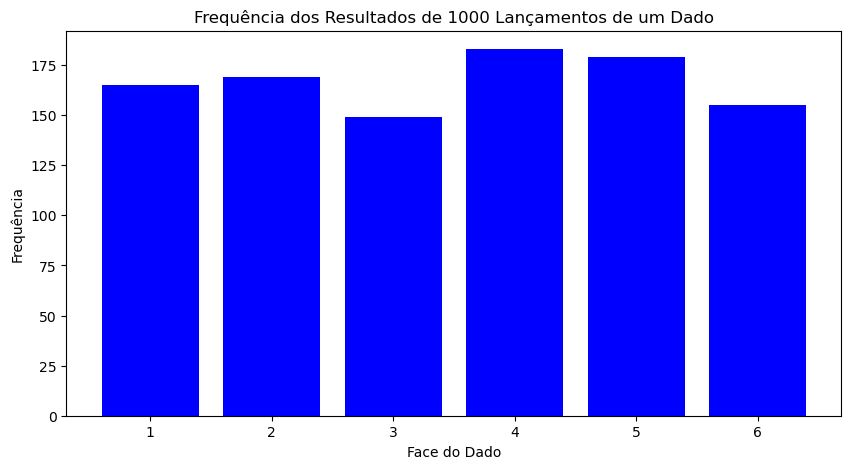

In [4]:
# Cria um gráfico de barras para mostrar a frequência de cada face
plt.figure(figsize = (10, 5))
faces = range(1, 7)
plt.bar(faces, frequencias, color = 'blue')
plt.xlabel('Face do Dado')
plt.ylabel('Frequência')
plt.title('Frequência dos Resultados de 1000 Lançamentos de um Dado')
plt.xticks(faces)
plt.show()

### Distribuição Binomial

Descreve o número de sucessos em n ensaios independentes de Bernoulli (experimentos com dois possíveis resultados, como sucesso e fracasso) com a mesma probabilidade de sucesso p. Por exemplo, o número de caras em 10 lançamentos de uma moeda.

O exemplo abaixo simula um cenário comum de lançamento de moeda, onde estamos interessados em encontrar a probabilidade de obter um determinado número de caras (sucesso) em um número fixo de lançamentos.

Imagine que você lança uma moeda justa 10 vezes e quer saber a probabilidade de obter exatamente 5 caras. A moeda justa significa que a probabilidade de cara (sucesso) é de 0,5 em cada lançamento.

In [5]:
#DEFINE OS PARAMETROS DA DISTRIBUIÇÃO BINOMIAL

#numero de ensaios (lançamentos da moeda)
n = 10 

#probabilidade de sucesso (cara) em cada ensaio
p = 0.5

#calcula a possibilidade de obter EXATAMENTE 5 sucessos (caras)
probabilidade = binom.pmf(5, 10, p)

print(f"\nA probabilidade de obter exatamente 5 caras em 10 lançamentos é de {probabilidade * 100:.2f}%")


A probabilidade de obter exatamente 5 caras em 10 lançamentos é de 24.61%


No código acima, **binom.pmf(k, n, p)** calcula a função de massa de probabilidade (probability mass function - pmf) da distribuição binomial, que é a probabilidade de obter k sucessos em n ensaios independentes, cada um com probabilidade de sucesso p. O resultado é a probabilidade de obter exatamente 5 caras (sucessos) quando você lança uma moeda justa 10 vezes.

Vamos criar o plot.

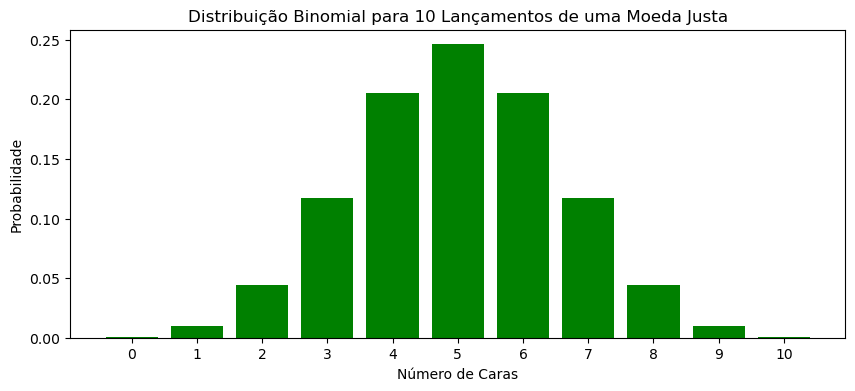

In [6]:
# Gera um gráfico da distribuição binomial
plt.figure(figsize = (10, 4))
x = range(n + 1)
y = binom.pmf(x, n, p)
plt.bar(x, y, color = 'green')
plt.xlabel('Número de Caras')
plt.ylabel('Probabilidade')
plt.title('Distribuição Binomial para 10 Lançamentos de uma Moeda Justa')
plt.xticks(x)
plt.show()

### Distribuição de Poisson

Usada para modelar o número de vezes que um evento acontece em um intervalo de tempo ou espaço fixo, quando esses eventos ocorrem com uma taxa média constante e independente do tempo desde o último evento. Por exemplo, o número de chamadas recebidas por um call center em uma hora.

Suponha que queremos modelar o número de chamadas que um call center recebe em uma hora. Se a taxa média de chamadas é de 10 chamadas por hora, podemos usar a distribuição de Poisson para calcular a probabilidade de receber um determinado número de chamadas, digamos 15, em uma hora.

"Se a taxa média de chamadas é de 10 chamadas por hora", ou seja, para esse tipo de distribuição, deve-se ter um regidtro histórico de dados.

In [7]:
# Define a taxa média de chamadas por hora
lambda_ = 10  # 'lambda' é a taxa média de eventos (chamadas) por intervalo (hora)

# Calcula a probabilidade de receber exatamente 15 chamadas em uma hora
probabilidade = poisson.pmf(15, lambda_)

print(f"\nA probabilidade de receber exatamente 15 chamadas em uma hora é de {probabilidade * 100:.2f}%")


A probabilidade de receber exatamente 15 chamadas em uma hora é de 3.47%


No código acima, **poisson.pmf(k, lambda_)** calcula a função de massa de probabilidade da distribuição de Poisson, que é a probabilidade de ocorrer k eventos em um intervalo fixo, dado uma taxa média de eventos lambda_ por intervalo. O resultado nos dá a probabilidade de receber exatamente 15 chamadas em uma hora, dado que a taxa média é de 10 chamadas por hora.

Vamos criar o plot.

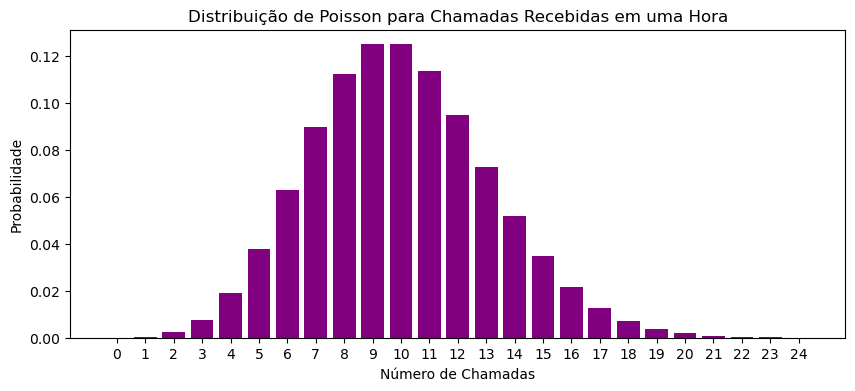

In [8]:
# Gera um gráfico da distribuição de Poisson
plt.figure(figsize = (10, 4))
x = range(0, 25)  # Define um intervalo de valores possíveis para o número de chamadas
y = poisson.pmf(x, lambda_)
plt.bar(x, y, color = 'purple')
plt.xlabel('Número de Chamadas')
plt.ylabel('Probabilidade')
plt.title('Distribuição de Poisson para Chamadas Recebidas em uma Hora')
plt.xticks(x)
plt.show()

### Distribuição Geométrica

Modela o número de ensaios de Bernoulli necessários para obter o primeiro sucesso. Por exemplo, o número de lançamentos de uma moeda até que saia cara pela primeira vez.

A distribuição geométrica modela o número de ensaios de Bernoulli (experimentos com dois possíveis resultados, sucesso ou fracasso) necessários para obter o primeiro sucesso, assumindo que a probabilidade de sucesso em cada ensaio é constante.

Por exemplo, consideremos o lançamento repetido de uma moeda justa, onde estamos interessados na probabilidade de que o primeiro "cara" (sucesso) ocorra no quinto lançamento. A probabilidade de sucesso (obter "cara") em cada lançamento é de 0.5.

In [9]:
# Define a probabilidade de sucesso em cada ensaio
p = 0.5  # Probabilidade de cara

# Calcula a probabilidade de o primeiro sucesso ocorrer no 5º lançamento
probabilidade = geom.pmf(5, p)

print(f"\nA probabilidade de o primeiro 'cara' ocorrer no 5º lançamento é de {probabilidade * 100:.2f}%")


A probabilidade de o primeiro 'cara' ocorrer no 5º lançamento é de 3.12%


Neste código, geom.pmf(k, p) calcula a função de massa de probabilidade para a distribuição geométrica, que é a probabilidade de que o primeiro sucesso ocorra no k-ésimo ensaio, dado que a probabilidade de sucesso em cada ensaio é p. O resultado nos dá a probabilidade de que o primeiro "cara" apareça especificamente no quinto lançamento de uma moeda.

Vamos criar o plot.

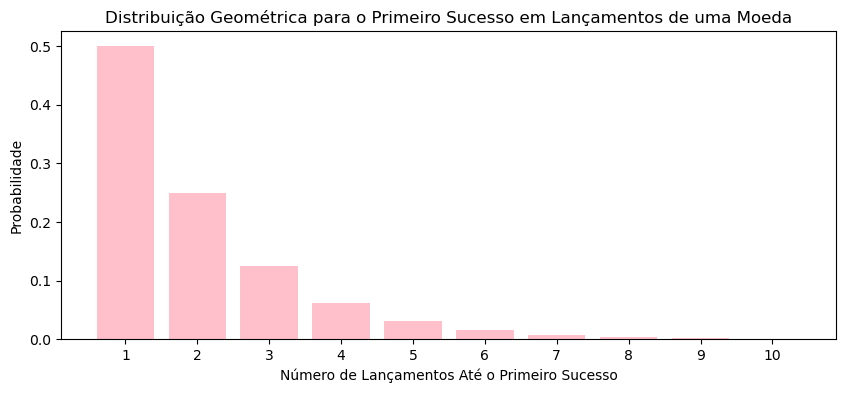

In [10]:
# Gera um gráfico da distribuição geométrica
plt.figure(figsize = (10, 4))
x = range(1, 11)  # Define um intervalo de valores possíveis para o número de lançamentos até o primeiro sucesso
y = geom.pmf(x, p)
plt.bar(x, y, color = 'pink')
plt.xlabel('Número de Lançamentos Até o Primeiro Sucesso')
plt.ylabel('Probabilidade')
plt.title('Distribuição Geométrica para o Primeiro Sucesso em Lançamentos de uma Moeda')
plt.xticks(x)
plt.show()